# Baseline Model — TF-IDF + Logistic Regression / SVM

Pikë referimi para fine-tuning të Transformer-ave (XLM-RoBERTa, DistilBERT).

## 1. Ngarkimi i të dhënave

In [ ]:
import pandas as pd

train_df = pd.read_csv('../data/processed/train.csv')
val_df = pd.read_csv('../data/processed/val.csv')
test_df = pd.read_csv('../data/processed/test.csv')

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

train_df.head()

Train: (75480, 4)
Validation: (16174, 4)
Test: (16175, 4)


,text_final,label,source,date
0,Gjëra tronditëse që mësuam nga Wikileaks: Fiks...,Botë,Bota_al,2016-10-14T16:17:57
1,A është argjentinasja ajo që i shton gjasat që...,Showbiz,GazetaBlic,2017-01-18 11:35:55
2,"Ronaldo, Aguerro apo Benzema? Cana tregon se c...",Sport,GazetaBlic,2017-01-23 11:50:40
3,"Luftojnë tensionin e lartë të gjakut, këto jan...",Shëndet,Lajme_al,2021-04-02 17:33:17
4,"Huamarrja me euro, qeveria ndryshon monedhën e...",Ekonomi,Lajme_al,2016-11-21 17:23:46


## 2. TF-IDF Vectorization

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.9
)

X_train = vectorizer.fit_transform(train_df['text_final'])
X_val = vectorizer.transform(val_df['text_final'])
X_test = vectorizer.transform(test_df['text_final'])

y_train = train_df['label']
y_val = val_df['label']
y_test = test_df['label']

print("Shape X_train:", X_train.shape)
print("Shape X_val:", X_val.shape)
print("Numri i fjalëve/n-grameve në fjalor:", len(vectorizer.vocabulary_))

Shape X_train: (75480, 20000)
Shape X_val: (16174, 20000)
Numri i fjalëve/n-grameve në fjalor: 20000


## 3. Trajnimi — Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
import time

start = time.time()
lr_model = LogisticRegression(max_iter=1000, random_state=42, n_jobs=-1)
lr_model.fit(X_train, y_train)
lr_training_time = time.time() - start

print(f"Koha e trajnimit: {lr_training_time:.2f} sekonda")

c:\Users\denis\Downloads\Desktop\diploma-project\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Koha e trajnimit: 15.95 sekonda


## 4. Vlerësimi — Logistic Regression (mbi Validation)

In [ ]:
from sklearn.metrics import classification_report, accuracy_score, f1_score

y_pred_lr = lr_model.predict(X_val)

print("Accuracy:", accuracy_score(y_val, y_pred_lr))
print("Macro F1:", f1_score(y_val, y_pred_lr, average='macro'))
print("\nClassification Report:")
print(classification_report(y_val, y_pred_lr))

Accuracy: 0.8411648324471374
Macro F1: 0.8404806132251471

Classification Report:
              precision    recall  f1-score   support

        Botë       0.86      0.86      0.86      1800
     Ekonomi       0.87      0.89      0.88      1798
     Kulturë       0.86      0.87      0.87      1798
 Kuriozitete       0.68      0.65      0.67      1798
   Lifestyle       0.69      0.64      0.66      1798
    Politikë       0.94      0.95      0.94      1799
     Showbiz       0.90      0.89      0.90      1799
     Shëndet       0.77      0.86      0.81      1799
       Sport       0.98      0.96      0.97      1785

    accuracy                           0.84     16174
   macro avg       0.84      0.84      0.84     16174
weighted avg       0.84      0.84      0.84     16174



## 5. Trajnimi — Linear SVM

In [ ]:
from sklearn.svm import LinearSVC

start = time.time()
svm_model = LinearSVC(random_state=42, max_iter=2000)
svm_model.fit(X_train, y_train)
svm_training_time = time.time() - start

print(f"Koha e trajnimit: {svm_training_time:.2f} sekonda")

Koha e trajnimit: 14.07 sekonda


## 6. Vlerësimi — SVM (mbi Validation)

In [ ]:
y_pred_svm = svm_model.predict(X_val)

print("Accuracy:", accuracy_score(y_val, y_pred_svm))
print("Macro F1:", f1_score(y_val, y_pred_svm, average='macro'))
print("\nClassification Report:")
print(classification_report(y_val, y_pred_svm))

Accuracy: 0.836094967231359
Macro F1: 0.834797812495088

Classification Report:
              precision    recall  f1-score   support

        Botë       0.86      0.86      0.86      1800
     Ekonomi       0.87      0.89      0.88      1798
     Kulturë       0.86      0.88      0.87      1798
 Kuriozitete       0.67      0.61      0.64      1798
   Lifestyle       0.66      0.63      0.65      1798
    Politikë       0.94      0.95      0.95      1799
     Showbiz       0.90      0.90      0.90      1799
     Shëndet       0.76      0.84      0.80      1799
       Sport       0.97      0.97      0.97      1785

    accuracy                           0.84     16174
   macro avg       0.83      0.84      0.83     16174
weighted avg       0.83      0.84      0.83     16174



## 7. Confusion Matrix (modeli më i mirë)

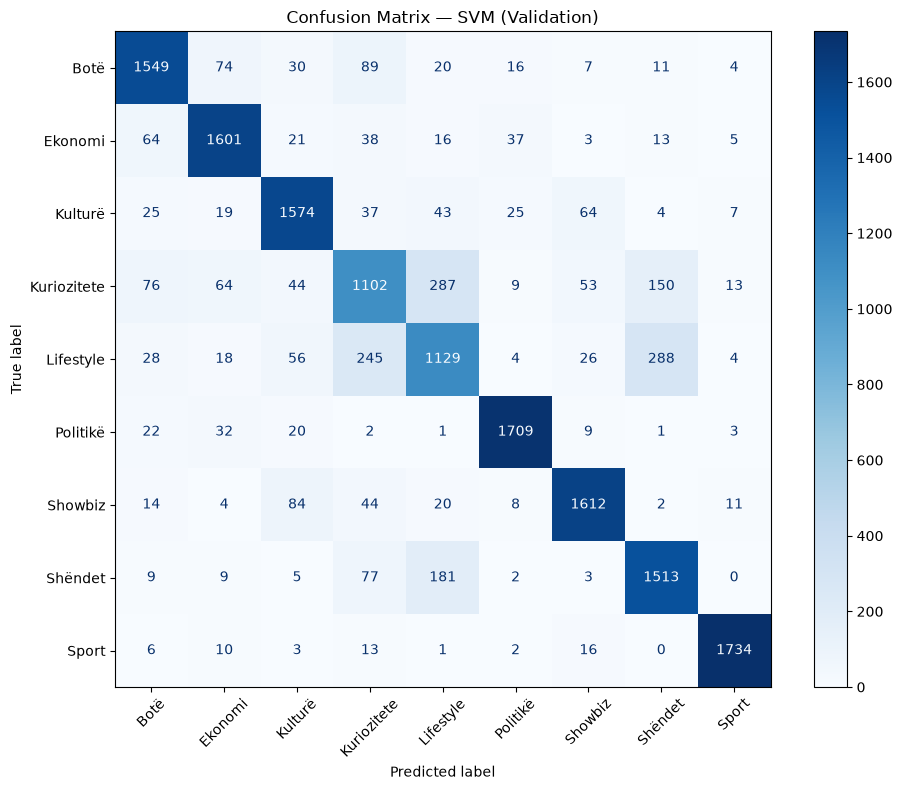

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_val, y_pred_svm,
    xticks_rotation=45,
    ax=ax,
    cmap='Blues'
)
plt.title("Confusion Matrix — SVM (Validation)")
plt.tight_layout()
plt.show()